# Off Market Models

In [4]:
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterGrid
from xgboost import XGBRegressor

import data
from features import square_feet

scores = []

def percentage_scores(predicted, sold):
    signed = 100 * (np.asarray(predicted) - np.asarray(sold)) / np.asarray(sold)
    absolute = np.abs(signed)
    return {
        "MdAPE": round(float(np.median(absolute)), 2),
        "MAPE": round(float(np.mean(absolute)), 2),
        "median_signed_error": round(float(np.median(signed)), 2),
    }


def add_score(name, predicted, sold):
    row = {"model": name, **percentage_scores(predicted, sold)}
    scores.append(row)
    print(
        f"{name}: MdAPE {row['MdAPE']:.2f}%, "
        f"MAPE {row['MAPE']:.2f}%, "
        f"median signed error {row['median_signed_error']:+.2f}%"
    )

    return row

### Data Split

In [5]:
listings = data.load("listings").copy()
listings["square_feet"] = square_feet(listings["house_area"])

holdout_start = pd.Timestamp("2025-12-01")
train = listings[listings["date_sold"] < holdout_start].copy()
valid = listings[listings["date_sold"] >= holdout_start].copy()
print(f"Train: {len(train):,} sales, {train['date_sold'].min():%Y-%m-%d} to {train['date_sold'].max():%Y-%m-%d}")
print(f"Validation: {len(valid):,} sales, {valid['date_sold'].min():%Y-%m-%d} to {valid['date_sold'].max():%Y-%m-%d}")

Train: 139,931 sales, 2021-01-01 to 2025-11-30
Validation: 10,069 sales, 2025-12-01 to 2026-05-31


## Numerical features

In [6]:
def numeric_design(frame):
    missing_lot = frame["lot_front"].isna()
    X = pd.DataFrame(index=frame.index)
    X["log_square_feet"] = np.log(frame["square_feet"])
    X["lot_missing"] = missing_lot.astype(float)
    X["log_lot_front"] = np.log(frame["lot_front"].where(~missing_lot, 1.0))
    X["lot_depth"] = frame["lot_depth"].fillna(0.0)
    for column in ["bedrooms", "washrooms", "parking_total", "garage", "latitude", "longitude"]:
        X[column] = frame[column].astype(float)
    return X

train_X = sm.add_constant(numeric_design(train),has_constant="add")
valid_X = sm.add_constant(numeric_design(valid), has_constant="add")
train_X.head()

,const,log_square_feet,lot_missing,log_lot_front,lot_depth,bedrooms,washrooms,parking_total,garage,latitude,longitude
0,1.0,6.432940,1.0,0.0,0.0,1.0,1.0,0.0,0.0,43.602039,-79.261184
1,1.0,6.475433,1.0,0.0,0.0,2.0,1.0,0.0,0.0,43.695388,-79.510865
2,1.0,6.907255,1.0,0.0,0.0,2.0,1.0,1.0,0.0,43.740512,-79.386216
3,1.0,6.775366,1.0,0.0,0.0,1.0,1.0,1.0,0.0,43.643774,-79.470180
4,1.0,6.242223,1.0,0.0,0.0,1.0,1.0,1.0,0.0,43.696172,-79.274137


## OLS

In [7]:
raw_columns = [
    "square_feet", "lot_front", "lot_depth",
    "bedrooms", "washrooms", "parking_total","garage", "latitude", "longitude"
]

def raw_design(frame):
    X = frame[raw_columns].copy()
    X["lot_front"] = X["lot_front"].fillna(0.0)
    X["lot_depth"] = X["lot_depth"].fillna(0.0)
    return sm.add_constant(X, has_constant="add")


raw_model = sm.OLS(train["sold_price"], raw_design(train)).fit()
raw_hat = raw_model.predict(raw_design(valid))

add_score("OLS, regular", raw_hat, valid["sold_price"])

OLS, regular: MdAPE 21.76%, MAPE 29.54%, median signed error +14.16%


{'model': 'OLS, regular',
 'MdAPE': 21.76,
 'MAPE': 29.54,
 'median_signed_error': 14.16}

## Log OLS

In [8]:
log_target = pd.Series(np.log(train["sold_price"]), index=train.index, name="log_sold_price")

log_model = sm.OLS(log_target, train_X).fit()
log_hat = np.exp(log_model.predict(valid_X))

add_score("OLS, log transformed", log_hat, valid["sold_price"])

OLS, log transformed: MdAPE 20.26%, MAPE 27.14%, median signed error +11.88%


{'model': 'OLS, log transformed',
 'MdAPE': 20.26,
 'MAPE': 27.14,
 'median_signed_error': 11.88}

### Comparing OLS models

Residual skew, regular: 5.79
Residual skew, log scale: 0.32
Regular regression:


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             sold_price   R-squared:                       0.625
Model:                            OLS   Adj. R-squared:                  0.625
Method:                 Least Squares   F-statistic:                 2.592e+04
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        21:01:26   Log-Likelihood:            -2.0337e+06
No. Observations:              139931   AIC:                         4.067e+06
Df Residuals:                  139921   BIC:                         4.068e+06
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const         -3.822e+06   1.58e+06     -2.418      0.016   -6.92e+06   -7.25e+05
square_feet     577.9961      2.649    218.161      0.000     572.803     583.189
lot_front      2376.8019    130.378     18.230      0.000    2121.263    2632.341
lot_depth      1979.3042     44.060     44.923      0.000    1892.948    2065.660
bedrooms      -9.954e+04   2063.399    -48.238      0.000   -1.04e+05   -9.55e+04
washrooms      1.159e+05   2053.347     56.451      0.000    1.12e+05     1.2e+05
parking_total -9483.8259   1324.675     -7.159      0.000   -1.21e+04   -6887.489
garage        -1.734e+04   2889.927     -5.999      0.000    -2.3e+04   -1.17e+04
latitude       2.845e+05   2.45e+04     11.588      0.000    2.36e+05    3.33e+05
longitude      1.063e+05   1.33e+04      8.016      0.000    8.03e+04    1.32e+05
==============================================================================
Omnibus:                   166266.586   Durbin-Watson:                   1.973
Prob(Omnibus):                  0.000   Jarque-Bera (JB):         85666586.935
Skew:                           5.788   Prob(JB):                         0.00
Kurtosis:                     123.660   Cond. No.                     1.96e+06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.96e+06. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Log-transformed regression:


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         log_sold_price   R-squared:                       0.713
Model:                            OLS   Adj. R-squared:                  0.713
Method:                 Least Squares   F-statistic:                 3.470e+04
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        21:01:26   Log-Likelihood:                -20363.
No. Observations:              139931   AIC:                         4.075e+04
Df Residuals:                  139920   BIC:                         4.086e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               7.2639      0.892      8.140      0.000       5.515       9.013
log_square_feet     0.4960      0.003    157.470      0.000       0.490       0.502
lot_missing         0.0486      0.010      4.861      0.000       0.029       0.068
log_lot_front       0.0461      0.003     15.540      0.000       0.040       0.052
lot_depth           0.0018   4.03e-05     44.577      0.000       0.002       0.002
bedrooms           -0.0519      0.001    -40.615      0.000      -0.054      -0.049
washrooms           0.1178      0.001    101.437      0.000       0.116       0.120
parking_total      -0.0092      0.001    -11.790      0.000      -0.011      -0.008
garage              0.0026      0.002      1.584      0.113      -0.001       0.006
latitude            0.2477      0.014     17.888      0.000       0.221       0.275
longitude           0.1028      0.007     13.735      0.000       0.088       0.117
==============================================================================
Omnibus:                     5400.907   Durbin-Watson:                   1.936
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             9507.853
Skew:                           0.323   Prob(JB):                         0.00
Kurtosis:                       4.102   Cond. No.                     1.30e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.3e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

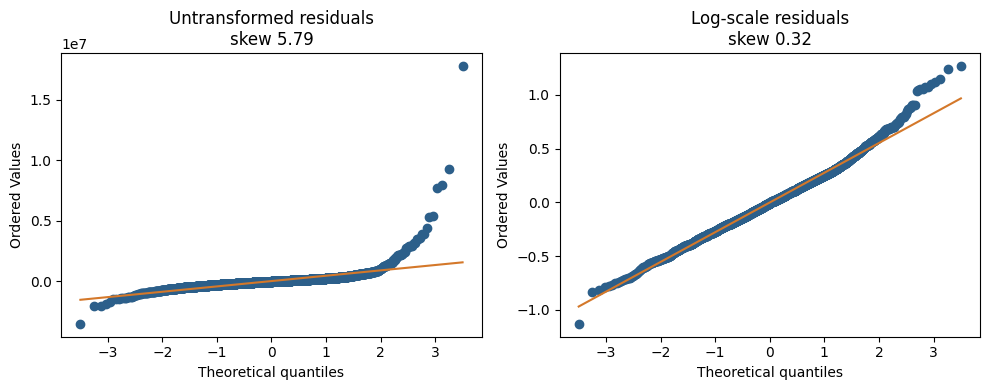

In [9]:
print(f"Residual skew, regular: {raw_model.resid.skew():.2f}")
print(f"Residual skew, log scale: {pd.Series(log_model.resid).skew():.2f}")

print("Regular regression:")
display(raw_model.summary())

print("Log-transformed regression:")
display(log_model.summary())

rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
panels = [
    (raw_model.resid, f"Untransformed residuals\nskew {raw_model.resid.skew():.2f}"),
    (log_model.resid, f"Log-scale residuals\nskew {pd.Series(log_model.resid).skew():.2f}")
]

for ax, (resid, title) in zip(axes, panels):
    sample = rng.choice(np.asarray(resid), size=min(3000, len(resid)), replace=False)
    stats.probplot(sample, dist="norm", plot=ax)
    ax.set_title(title)
    ax.get_lines()[0].set_color("#2c5f8a")
    ax.get_lines()[1].set_color("#d4782a")
fig.tight_layout()
plt.show()

### Feature Engineering

In [10]:
def tree_frame(frame):
    X = numeric_design(frame)
    listed_month = frame["date_listed"].dt.month.to_numpy()
    X["listed_month_sin"] = np.sin(2 * np.pi * listed_month / 12)
    X["listed_month_cos"] = np.cos(2 * np.pi * listed_month / 12)
    return X

tree_train = tree_frame(train)
tree_valid = tree_frame(valid)

log_sold = np.log(train["sold_price"].to_numpy())

In [11]:
tune_start = pd.Timestamp("2025-07-01")
fit_mask = (train["date_sold"] < tune_start).to_numpy()
X_fit = tree_train.iloc[fit_mask]
y_fit = np.log(train["sold_price"].to_numpy()[fit_mask])
X_tune = tree_train.iloc[~fit_mask]
sold_tune = train["sold_price"].to_numpy()[~fit_mask]
print(
    f"Parameter search: fit {fit_mask.sum():,} sales through June 2025, "
    f"score {(~fit_mask).sum():,} sales from July through November 2025"
)

def inner_mdape(model):
    model.fit(X_fit, y_fit)
    predicted = np.exp(model.predict(X_tune))
    error = np.abs(predicted - sold_tune) / sold_tune
    return round(float(np.median(error) * 100), 3)

def validation_score(name, model):
    model.fit(tree_train, log_sold)
    predicted = np.exp(model.predict(tree_valid))
    return add_score(name, predicted, valid["sold_price"])

Parameter search: fit 130,045 sales through June 2025, score 9,886 sales from July through November 2025


## XGBoost

In [12]:
xgb_candidates = list(ParameterGrid(
    {
        "max_depth": [4, 6, 8],
        "learning_rate": [0.05, 0.1],
        "n_estimators": [200, 400],
    }
))

xgb_candidates.extend([
    {
        "max_depth": 8,
        "learning_rate": 0.05,
        "n_estimators": 600,
    },
    {
        "max_depth": 8,
        "learning_rate": 0.03,
        "n_estimators": 600,
    },
    {
        "max_depth": 10,
        "learning_rate": 0.05,
        "n_estimators": 400,
    },
    {
        "max_depth": 10,
        "learning_rate": 0.05,
        "n_estimators": 600,
    },
])

xgb_rows = []

for params in xgb_candidates:
    score = inner_mdape(
        XGBRegressor(
            **params,
            min_child_weight=20,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            tree_method="hist",
            n_jobs=-1,
            random_state=0,
            verbosity=0,
        )
    )

    xgb_rows.append({**params, "inner_MdAPE": score})


xgb_table = pd.DataFrame(xgb_rows).sort_values(
    ["inner_MdAPE", "n_estimators", "max_depth", "learning_rate"]
).reset_index(drop=True)

display(xgb_table)
best_xgb = xgb_table.iloc[0]
validation_score(
    f"XGBoost, depth {int(best_xgb.max_depth)}, lr {best_xgb.learning_rate:g}, {int(best_xgb.n_estimators)} trees",
    XGBRegressor(
        n_estimators=int(best_xgb.n_estimators),
        max_depth=int(best_xgb.max_depth),
        learning_rate=float(best_xgb.learning_rate),
        min_child_weight=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        tree_method="hist",
        n_jobs=-1,
        random_state=0,
        verbosity=0,
    ),
)

,learning_rate,max_depth,n_estimators,inner_MdAPE
0,0.05,10,600,15.470
1,0.05,10,400,15.633
2,0.10,8,400,15.725
3,0.05,8,600,15.873
4,0.05,8,400,16.275
5,0.03,8,600,16.279
6,0.10,6,400,16.355
7,0.10,8,200,16.369
8,0.10,6,200,16.969
9,0.05,8,200,17.000


XGBoost, depth 10, lr 0.05, 600 trees: MdAPE 17.28%, MAPE 21.17%, median signed error +14.00%


{'model': 'XGBoost, depth 10, lr 0.05, 600 trees',
 'MdAPE': 17.28,
 'MAPE': 21.17,
 'median_signed_error': 14.0}

## CatBoost

In [14]:
from catboost import CatBoostRegressor

cat_candidates = list(ParameterGrid(
    {
        "depth": [6, 8],
        "learning_rate": [0.05, 0.1],
        "l2_leaf_reg": [3, 10],
    }
))

cat_candidates.extend([
    {
        "depth": 6,
        "learning_rate": 0.15,
        "l2_leaf_reg": 3,
    },
    {
        "depth": 6,
        "learning_rate": 0.15,
        "l2_leaf_reg": 1,
    },
])

cat_rows = []
for params in cat_candidates:
    score = inner_mdape(
        CatBoostRegressor(
            **params,
            iterations=300,
            loss_function="RMSE",
            random_seed=0,
            verbose=0,
            allow_writing_files=False,
            thread_count=-1,
        )
    )
    cat_rows.append({**params, "inner_MdAPE": score})
cat_table = pd.DataFrame(cat_rows).sort_values(
    ["inner_MdAPE", "depth", "l2_leaf_reg", "learning_rate"]
).reset_index(drop=True)
display(cat_table)
best_cat = cat_table.iloc[0]
validation_score(
    f"CatBoost, depth {int(best_cat.depth)}, lr {best_cat.learning_rate:g}, l2 {best_cat.l2_leaf_reg:g}",
    CatBoostRegressor(
        depth=int(best_cat.depth),
        learning_rate=float(best_cat.learning_rate),
        l2_leaf_reg=float(best_cat.l2_leaf_reg),
        iterations=300,
        loss_function="RMSE",
        random_seed=0,
        verbose=0,
        allow_writing_files=False,
        thread_count=-1,
    ),
)

CatBoost, depth 8, lr 0.1, l2 3: MdAPE 18.61%, MAPE 23.31%, median signed error +13.66%


,depth,l2_leaf_reg,learning_rate,inner_MdAPE
0,8,3,0.10,17.038
1,8,10,0.10,17.132
2,6,3,0.15,17.161
3,6,1,0.15,17.307
4,6,10,0.10,17.654
5,6,3,0.10,17.720
6,8,3,0.05,17.892
7,8,10,0.05,17.941
8,6,10,0.05,18.322
9,6,3,0.05,18.347


## Random Forest

In [13]:
rf_rows = []
for params in ParameterGrid(
    {
        "max_depth": [12, 20, 32],
        "min_samples_leaf": [5, 20],
    }
):
    score = inner_mdape(
        RandomForestRegressor(
            **params,
            n_estimators=200,
            max_features=0.5,
            n_jobs=-1,
            random_state=0,
        )
    )
    rf_rows.append({**params, "inner_MdAPE": score})

rf_table = pd.DataFrame(rf_rows).sort_values(
    ["inner_MdAPE", "max_depth", "min_samples_leaf"],
    ascending=[True, True, False],
).reset_index(drop=True)

display(rf_table)
best_rf = rf_table.iloc[0]
validation_score(
    f"Random Forest, depth {int(best_rf.max_depth)}, leaf {int(best_rf.min_samples_leaf)}",
    RandomForestRegressor(
        n_estimators=200,
        max_depth=int(best_rf.max_depth),
        min_samples_leaf=int(best_rf.min_samples_leaf),
        max_features=0.5,
        n_jobs=-1,
        random_state=0,
    ),
)

,max_depth,min_samples_leaf,inner_MdAPE
0,32,5,17.442
1,20,5,17.605
2,32,20,18.387
3,20,20,18.444
4,12,5,19.118
5,12,20,19.207


Random Forest, depth 32, leaf 5: MdAPE 18.95%, MAPE 23.63%, median signed error +13.93%


{'model': 'Random Forest, depth 32, leaf 5',
 'MdAPE': 18.95,
 'MAPE': 23.63,
 'median_signed_error': 13.93}

## V1: Recent community dollars per square foot

Square feet times the median sold dollars per square foot of earlier sales in the same community and house type. Only sales from a recent window of months before the listing month are used. Fewer than 30 sales falls back to the house type, then to the city. The window is chosen on sales from July through November 2025. December 2025 through May 2026 is scored once, with the price levels taken from sales before December.


In [30]:
def month_ord(dates):
    return (dates.dt.year * 12 + dates.dt.month).to_numpy()


def recent_psf_table(reference, group_columns, window):
    history = reference.loc[:, group_columns].copy()
    history["month_ord"] = month_ord(reference["date_sold"])
    history["value"] = (reference["sold_price"] / reference["square_feet"]).to_numpy(dtype=float)
    history = history.replace([np.inf, -np.inf], np.nan).dropna()
    last_month = int(history["month_ord"].max())
    query_ords = np.arange(int(history["month_ord"].min()) - 24, last_month + 18)
    pieces = []
    for key, group in history.groupby(group_columns, observed=True, sort=False):
        group = group.sort_values("month_ord")
        sale_ords = group["month_ord"].to_numpy()
        values = group["value"].to_numpy()
        medians = np.full(len(query_ords), np.nan)
        counts = np.zeros(len(query_ords), dtype=float)
        for i, query in enumerate(query_ords):
            end = int(np.searchsorted(sale_ords, query, side="left"))
            if end == 0:
                continue
            start = int(np.searchsorted(sale_ords, query - window, side="left"))
            if start >= end:
                last = int(sale_ords[end - 1])
                start = int(np.searchsorted(sale_ords, last - window + 1, side="left"))
            medians[i] = float(np.median(values[start:end]))
            counts[i] = end - start
        key = key if isinstance(key, tuple) else (key,)
        piece = {"month_ord": query_ords, "median": medians, "count": counts}
        for column, value in zip(group_columns, key):
            piece[column] = value
        pieces.append(pd.DataFrame(piece))
    return pd.concat(pieces, ignore_index=True)


def lookup_past(query, table, group_columns):
    keys = query.loc[:, list(group_columns)].copy()
    keys["month_ord"] = month_ord(query["date_listed"])
    merged = keys.merge(table, on=list(group_columns) + ["month_ord"], how="left")
    if len(merged) != len(query):
        raise ValueError("past-median lookup changed the number of rows")
    median = merged["median"].to_numpy(dtype=float)
    count = merged["count"].fillna(0).to_numpy(dtype=float)
    return median, count


def psf_bundle(reference, window):
    usable = reference[(reference["sold_price"] > 0) & (reference["square_feet"] > 0)].copy()
    usable["_all"] = "all"
    return {
        "frame": usable,
        "fallback": float(np.median(usable["sold_price"] / usable["square_feet"])),
        "community": recent_psf_table(usable, ["community", "house_type_name"], window),
        "type": recent_psf_table(usable, ["house_type_name"], window),
        "city": recent_psf_table(usable, ["_all"], window),
    }


def price_level(frame, bundle):
    query = frame.copy()
    query["_all"] = "all"
    community_median, community_count = lookup_past(query, bundle["community"], ["community", "house_type_name"])
    type_median, type_count = lookup_past(query, bundle["type"], ["house_type_name"])
    city_median, city_count = lookup_past(query, bundle["city"], ["_all"])
    level = np.where(community_count >= 30, community_median, np.where(type_count >= 30, type_median, city_median))
    level = np.where(np.isfinite(level) & (level > 0), level, bundle["fallback"])
    return level, community_count >= 30


def anchor_price(frame, bundle):
    level, community_hit = price_level(frame, bundle)
    return level * frame["square_feet"].to_numpy(dtype=float), community_hit


screen = train[train["date_sold"] >= "2025-07-01"]
window_rows = []
for window, label in [(3, "3 months"), (6, "6 months"), (12, "12 months"), (24, "24 months"), (240, "all history")]:
    print(f"screening {label}", flush=True)
    bundle = psf_bundle(train, window)
    predicted, community_hit = anchor_price(screen, bundle)
    row = {
        "window": label,
        "months": window,
        "community_share": round(100 * float(community_hit.mean()), 1),
        **percentage_scores(predicted, screen["sold_price"]),
    }
    window_rows.append(row)
    print(
        f"{label}: MdAPE {row['MdAPE']:.2f}, MAPE {row['MAPE']:.2f}, "
        f"signed {row['median_signed_error']:+.2f}, community {row['community_share']:.1f}%",
        flush=True,
    )
window_table = pd.DataFrame(window_rows).sort_values(["MdAPE", "MAPE"]).reset_index(drop=True)
display(window_table)
chosen_window = int(window_table.iloc[0]["months"])
chosen_label = window_table.iloc[0]["window"]
print(f"Chosen window: {chosen_label}")

v1_bundle = psf_bundle(train, chosen_window)
v1_hat, v1_community = anchor_price(valid, v1_bundle)
print(
    f"Validation community level: {100 * float(v1_community.mean()):.1f}% of homes. "
    f"Type or city fallback: {100 * float((~v1_community).mean()):.1f}%."
)
add_score(f"V1 recent community $/sqft, {chosen_label}", v1_hat, valid["sold_price"])
if chosen_window != 240:
    history_bundle = psf_bundle(train, 240)
    history_hat, _ = anchor_price(valid, history_bundle)
    add_score("V1 check, all-history community $/sqft", history_hat, valid["sold_price"])
all_history_score = next(
    row["MdAPE"] for row in scores if "all history" in row["model"] or "all-history" in row["model"]
)
if abs(all_history_score - 17.07) > 0.8:
    raise RuntimeError(f"all-history MdAPE {all_history_score} is far from the EDA baseline 17.07")


screening 3 months
3 months: MdAPE 17.21, MAPE 24.19, signed +4.30, community 35.0%
screening 6 months
6 months: MdAPE 16.19, MAPE 22.78, signed +6.54, community 61.0%
screening 12 months
12 months: MdAPE 15.33, MAPE 21.46, signed +6.95, community 79.9%
screening 24 months
24 months: MdAPE 15.70, MAPE 21.64, signed +9.18, community 89.8%
screening all history
all history: MdAPE 16.42, MAPE 22.44, signed +11.97, community 96.9%


,window,months,community_share,MdAPE,MAPE,median_signed_error
0,12 months,12,79.9,15.33,21.46,6.95
1,24 months,24,89.8,15.70,21.64,9.18
2,6 months,6,61.0,16.19,22.78,6.54
3,all history,240,96.9,16.42,22.44,11.97
4,3 months,3,35.0,17.21,24.19,4.30


Chosen window: 12 months
Validation community level: 76.5% of homes. Type or city fallback: 23.5%.
V1 recent community $/sqft, 12 months: MdAPE 15.60%, MAPE 20.80%, median signed error +3.71%
V1 check, all-history community $/sqft: MdAPE 17.07%, MAPE 22.23%, median signed error +10.84%


## V2: Level shift on the recent price

V1's all-history price sits above the 2025 market. The shift is the median log miss of the chosen V1 window on September through November 2025, using price levels built only from sales before September. The December 2025 through May 2026 prediction uses price levels from all sales before December, multiplied by exp(−shift).


In [31]:
early = train[train["date_sold"] < "2025-09-01"]
recent_check = train[train["date_sold"] >= "2025-09-01"]
early_bundle = psf_bundle(early, chosen_window)
recent_anchor, _ = anchor_price(recent_check, early_bundle)
v2_shift = float(np.median(np.log(recent_anchor) - np.log(recent_check["sold_price"].to_numpy())))
print(f"September-November shift: predictions high by {100 * (np.exp(v2_shift) - 1):+.2f}%")
v2_hat = v1_hat * np.exp(-v2_shift)
add_score(f"V2 V1 with level shift, {chosen_label}", v2_hat, valid["sold_price"])


September-November shift: predictions high by +7.15%
V2 V1 with level shift, 12 months: MdAPE 15.22%, MAPE 19.40%, median signed error -3.22%


## V3: LightGBM on the gap around V1

The target is log(sold price / V1 anchor). The features are the numeric size, lot, and coordinate fields, the listing-month sine and cosine, the log of the recent community price and of the 3-month and 12-month citywide prices, plus house type, style, community, and municipality as categories. Category levels and price tables come from sales before December 2025. The trees use the list-aware settings: 127 leaves, learning rate 0.03, 700 trees.


In [32]:
from lightgbm import LGBMRegressor

GAP_CATEGORIES = ["house_type_name", "house_style", "community", "municipality"]
PHRASE_PATTERNS = [
    ("as_is", r"as-is|as is"),
    ("turnkey", r"turnkey"),
    ("potential", r"potential"),
    ("original", r"original"),
    ("finished", r"finished"),
    ("renovated", r"renovat"),
    ("needs_work", r"needs work"),
    ("stunning", r"stunning|beautiful|gorgeous|spectacular"),
]
gap_lgb = dict(
    num_leaves=127,
    learning_rate=0.03,
    n_estimators=700,
    min_child_samples=20,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=0,
    n_jobs=-1,
    verbosity=-1,
)


def city_bundle(reference, window):
    usable = reference[(reference["sold_price"] > 0) & (reference["square_feet"] > 0)].copy()
    usable["_all"] = "all"
    return {
        "frame": usable,
        "fallback": float(np.median(usable["sold_price"] / usable["square_feet"])),
        "city": recent_psf_table(usable, ["_all"], window),
    }


def city_level(frame, bundle):
    query = frame.copy()
    query["_all"] = "all"
    median, count = lookup_past(query, bundle["city"], ["_all"])
    return np.where(np.isfinite(median) & (median > 0), median, bundle["fallback"])


def phrase_frame(frame):
    text = frame["remarks"].fillna("").str.lower()
    columns = pd.DataFrame(index=frame.index)
    for name, pattern in PHRASE_PATTERNS:
        columns[name] = text.str.contains(pattern, regex=True).astype(float).to_numpy()
    return columns


def gap_design(frame, anchor_bundle, city3, city12, levels, use_phrases):
    level, _ = price_level(frame, anchor_bundle)
    X = tree_frame(frame)
    X["log_community_psf"] = np.log(level)
    X["log_city_psf_3"] = np.log(city_level(frame, city3))
    X["log_city_psf_12"] = np.log(city_level(frame, city12))
    for column in GAP_CATEGORIES:
        X[column] = pd.Categorical(frame[column].to_numpy(), categories=levels[column])
    if use_phrases:
        phrases = phrase_frame(frame)
        for column in phrases.columns:
            X[column] = phrases[column].to_numpy()
    anchor = level * frame["square_feet"].to_numpy(dtype=float)
    return X, anchor


def category_levels(reference):
    return {column: pd.Index(reference[column].dropna().unique()) for column in GAP_CATEGORIES}


def fit_gap(fit_frame, reference, window, use_phrases):
    anchor_bundle = psf_bundle(reference, window)
    city3 = city_bundle(reference, 3)
    city12 = city_bundle(reference, 12)
    levels = category_levels(reference)
    X, anchor = gap_design(fit_frame, anchor_bundle, city3, city12, levels, use_phrases)
    model = LGBMRegressor(**gap_lgb)
    model.fit(X, np.log(fit_frame["sold_price"].to_numpy() / anchor), categorical_feature=GAP_CATEGORIES)
    return model, anchor_bundle, city3, city12, levels


def predict_gap(model, frame, anchor_bundle, city3, city12, levels, use_phrases):
    X, anchor = gap_design(frame, anchor_bundle, city3, city12, levels, use_phrases)
    return anchor * np.exp(model.predict(X))


print("Fitting V3", flush=True)
v3_model, v3_bundle, v3_city3, v3_city12, v3_levels = fit_gap(train, train, chosen_window, False)
v3_hat = predict_gap(v3_model, valid, v3_bundle, v3_city3, v3_city12, v3_levels, False)
add_score(f"V3 LightGBM on the V1 gap, {chosen_label}", v3_hat, valid["sold_price"])


Fitting V3
V3 LightGBM on the V1 gap, 12 months: MdAPE 9.40%, MAPE 12.13%, median signed error +1.03%


## V4: Level shift on V3

The shift is the median log miss of a V3 model fit only on sales before September 2025, scored on September through November 2025. Price levels for that fit come from the sales before September. The model is then refit on all sales before December and the same shift is applied.


In [33]:
print("Fitting V4 shift model", flush=True)
v4_early_model, v4_early_bundle, v4_early_city3, v4_early_city12, v4_early_levels = fit_gap(
    early, early, chosen_window, False
)
v4_recent_hat = predict_gap(
    v4_early_model, recent_check, v4_early_bundle, v4_early_city3, v4_early_city12, v4_early_levels, False
)
v4_shift = float(np.median(np.log(v4_recent_hat) - np.log(recent_check["sold_price"].to_numpy())))
print(f"September-November shift: predictions high by {100 * (np.exp(v4_shift) - 1):+.2f}%")
print("Refitting V4", flush=True)
v4_model, v4_bundle, v4_city3, v4_city12, v4_levels = fit_gap(train, train, chosen_window, False)
v4_hat = predict_gap(v4_model, valid, v4_bundle, v4_city3, v4_city12, v4_levels, False) * np.exp(-v4_shift)
add_score(f"V4 V3 with level shift, {chosen_label}", v4_hat, valid["sold_price"])


Fitting V4 shift model
September-November shift: predictions high by +2.34%
Refitting V4
V4 V3 with level shift, 12 months: MdAPE 9.23%, MAPE 11.88%, median signed error -1.28%


## V5: Condition phrases

V4's features plus indicators read from the remarks: as-is, turnkey, potential, original, finished, renovated, needs work, and stunning or beautiful. The level shift is measured again for this feature set, on September through November 2025, from a model fit only before September.


In [34]:
print("Fitting V5 shift model", flush=True)
v5_early_model, v5_early_bundle, v5_early_city3, v5_early_city12, v5_early_levels = fit_gap(
    early, early, chosen_window, True
)
v5_recent_hat = predict_gap(
    v5_early_model, recent_check, v5_early_bundle, v5_early_city3, v5_early_city12, v5_early_levels, True
)
v5_shift = float(np.median(np.log(v5_recent_hat) - np.log(recent_check["sold_price"].to_numpy())))
print(f"September-November shift: predictions high by {100 * (np.exp(v5_shift) - 1):+.2f}%")
print("Refitting V5", flush=True)
v5_model, v5_bundle, v5_city3, v5_city12, v5_levels = fit_gap(train, train, chosen_window, True)
v5_hat = predict_gap(v5_model, valid, v5_bundle, v5_city3, v5_city12, v5_levels, True) * np.exp(-v5_shift)
add_score(f"V5 condition phrases with level shift, {chosen_label}", v5_hat, valid["sold_price"])


Fitting V5 shift model
September-November shift: predictions high by +2.43%
Refitting V5
V5 condition phrases with level shift, 12 months: MdAPE 8.97%, MAPE 11.19%, median signed error -1.33%


# COMPARE MODELS

In [15]:
results = pd.DataFrame(scores)

results = results.sort_values(
    ["MdAPE", "MAPE"]
).reset_index(drop=True)

display(results)

,model,MdAPE,MAPE,median_signed_error
0,"V5 condition phrases with level shift, 12 months",8.97,11.19,-1.33
1,"V4 V3 with level shift, 12 months",9.23,11.88,-1.28
2,"V3 LightGBM on the V1 gap, 12 months",9.40,12.13,1.03
3,"V2 V1 with level shift, 12 months",15.22,19.40,-3.22
4,"V1 recent community $/sqft, 12 months",15.60,20.80,3.71
5,"V1 check, all-history community $/sqft",17.07,22.23,10.84
6,"XGBoost, depth 10, lr 0.05, 600 trees",17.28,21.17,14.00
7,"CatBoost, depth 8, lr 0.1, l2 3",18.61,23.31,13.66
8,"Random Forest, depth 32, leaf 5",18.95,23.63,13.93
9,"OLS, log transformed",20.26,27.14,11.88


## Walk-forward validation

December 2025 through May 2026, one month at a time. Each month is predicted from sales that closed before it. Community price levels, category levels, and the level shift are rebuilt from those sales. The shift uses the three months before the scored month and a model fit only before those three months. These scores are separate from the single fit in the comparison table.


In [35]:
walk_months = pd.period_range("2025-12", "2026-05", freq="M")
walk_parts = {name: [] for name in ["V1", "V2", "V4", "V5"]}
walk_sold_parts = []
walk_rows = []
for month in walk_months:
    past = listings[listings["date_sold"] < month.start_time].copy()
    homes = listings[listings["date_sold"].dt.to_period("M") == month].copy()
    sold = homes["sold_price"].to_numpy()
    early_cut = (month - 3).start_time
    month_early = past[past["date_sold"] < early_cut].copy()
    month_check = past[past["date_sold"] >= early_cut].copy()

    past_bundle = psf_bundle(past, chosen_window)
    early_bundle = psf_bundle(month_early, chosen_window)
    v1_month, _ = anchor_price(homes, past_bundle)
    check_anchor, _ = anchor_price(month_check, early_bundle)
    month_v2_shift = float(np.median(np.log(check_anchor) - np.log(month_check["sold_price"].to_numpy())))
    v2_month = v1_month * np.exp(-month_v2_shift)

    print(f"{month}: fitting V4", flush=True)
    early_model, early_anchor, early_city3, early_city12, early_levels = fit_gap(
        month_early, month_early, chosen_window, False
    )
    check_hat = predict_gap(early_model, month_check, early_anchor, early_city3, early_city12, early_levels, False)
    month_v4_shift = float(np.median(np.log(check_hat) - np.log(month_check["sold_price"].to_numpy())))
    full_model, full_anchor, full_city3, full_city12, full_levels = fit_gap(
        past, past, chosen_window, False
    )
    v4_month = predict_gap(full_model, homes, full_anchor, full_city3, full_city12, full_levels, False) * np.exp(-month_v4_shift)

    print(f"{month}: fitting V5", flush=True)
    early_model, early_anchor, early_city3, early_city12, early_levels = fit_gap(
        month_early, month_early, chosen_window, True
    )
    check_hat = predict_gap(early_model, month_check, early_anchor, early_city3, early_city12, early_levels, True)
    month_v5_shift = float(np.median(np.log(check_hat) - np.log(month_check["sold_price"].to_numpy())))
    full_model, full_anchor, full_city3, full_city12, full_levels = fit_gap(
        past, past, chosen_window, True
    )
    v5_month = predict_gap(full_model, homes, full_anchor, full_city3, full_city12, full_levels, True) * np.exp(-month_v5_shift)

    month_hats = {"V1": v1_month, "V2": v2_month, "V4": v4_month, "V5": v5_month}
    for name, hat in month_hats.items():
        walk_parts[name].append(hat)
    walk_sold_parts.append(sold)
    row = {"month": str(month)}
    for name, hat in month_hats.items():
        scores_month = percentage_scores(hat, sold)
        row[f"{name}_MdAPE"] = scores_month["MdAPE"]
        row[f"{name}_signed"] = scores_month["median_signed_error"]
    row["V2_shift"] = round(100 * (np.exp(month_v2_shift) - 1), 2)
    row["V4_shift"] = round(100 * (np.exp(month_v4_shift) - 1), 2)
    row["V5_shift"] = round(100 * (np.exp(month_v5_shift) - 1), 2)
    walk_rows.append(row)
    print(
        f"{month}: V1 {row['V1_MdAPE']:.2f}, V2 {row['V2_MdAPE']:.2f}, "
        f"V4 {row['V4_MdAPE']:.2f}, V5 {row['V5_MdAPE']:.2f}",
        flush=True,
    )

walk_sold = np.concatenate(walk_sold_parts)
walk_month_table = pd.DataFrame(walk_rows)
walk_summary = pd.DataFrame([
    {"model": name, **percentage_scores(np.concatenate(walk_parts[name]), walk_sold)}
    for name in ["V1", "V2", "V4", "V5"]
])
display(walk_month_table)
display(walk_summary)


2025-12: fitting V4
2025-12: fitting V5
2025-12: V1 16.57, V2 15.51, V4 8.81, V5 8.73
2026-01: fitting V4
2026-01: fitting V5
2026-01: V1 15.43, V2 14.09, V4 9.15, V5 8.66
2026-02: fitting V4
2026-02: fitting V5
2026-02: V1 15.61, V2 15.23, V4 9.36, V5 8.83
2026-03: fitting V4
2026-03: fitting V5
2026-03: V1 14.79, V2 14.76, V4 8.77, V5 8.34
2026-04: fitting V4
2026-04: fitting V5
2026-04: V1 15.02, V2 14.97, V4 8.76, V5 8.46
2026-05: fitting V4
2026-05: fitting V5
2026-05: V1 15.28, V2 15.10, V4 9.51, V5 8.81


,month,V1_MdAPE,V1_signed,V2_MdAPE,V2_signed,V4_MdAPE,V4_signed,V5_MdAPE,V5_signed,V2_shift,V4_shift,V5_shift
0,2025-12,16.57,9.72,15.51,2.39,8.81,0.14,8.73,0.25,7.15,2.34,2.43
1,2026-01,15.43,7.05,14.09,-0.97,9.15,-1.75,8.66,-2.18,8.09,2.63,2.86
2,2026-02,15.61,4.02,15.23,-4.49,9.36,-4.07,8.83,-4.27,8.91,3.74,3.98
3,2026-03,14.79,1.58,14.76,-5.16,8.77,-1.47,8.34,-1.26,7.10,1.49,1.45
4,2026-04,15.02,0.99,14.97,-2.83,8.76,0.03,8.46,-0.01,3.93,0.43,0.30
5,2026-05,15.28,-0.08,15.10,-2.10,9.51,-0.49,8.81,-1.15,2.06,-0.23,-0.03


,model,MdAPE,MAPE,median_signed_error
0,V1,15.33,20.32,3.19
1,V2,14.96,19.11,-2.42
2,V4,9.04,11.70,-1.11
3,V5,8.64,10.89,-1.29
